# Fase 2 CRISP-DM — Comprensión de los Datos (EDA)

Este cuaderno explora el inventario combinado del proyecto:
- **Fotos propias validadas por el equipo** (`data/own_photos/`, 6 especies).
- **Recortes individuales segmentados de `Mixed Qualit_Fruits`** (`data/mixed_crops/`).
- **Muestra estratificada de Kaggle *Fruit Quality Classification*** (`data/external/`).

Se analiza el balanceo de clases, la cobertura por especie y origen, la variabilidad de resoluciones/relaciones de aspecto y ejemplos visuales reales por categoría.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import FRUITNET_SPLITS_CSV, OWN_ANNOTATIONS_CSV, QUALITY_CLASSES

df = pd.read_csv(FRUITNET_SPLITS_CSV)
own_df = pd.read_csv(OWN_ANNOTATIONS_CSV)
print(f"Total dataset combinado: {len(df)} imágenes | Fotos propias: {len(own_df)}")
display(df.head())

Total dataset combinado: 971 imágenes | Fotos propias: 307


,image_path,species,quality,width,height,sha256,source,group_id,leakage_group,split
0,data/own_photos/banano/Buena/banano_001_buena.jpg,banano,Buena,466,1024,761bf6dc4675361c562afa7a23f4ee5986410138ad7451...,Propia,own_banano_761bf6dc4675,grp_0000,val
1,data/own_photos/banano/Buena/banano_002_buena.jpg,banano,Buena,541,1024,6d8b6891dd4edfc8fb937821bd743fd206399be2b39956...,Propia,own_banano_6d8b6891dd4e,grp_0001,train
2,data/own_photos/banano/Buena/banano_003_buena.jpg,banano,Buena,527,1024,f4459f990532491c853229390e4ed0229d1a2bd21f2223...,Propia,own_banano_f4459f990532,grp_0002,train
3,data/own_photos/banano/Buena/banano_004_buena.jpg,banano,Buena,502,1024,1c881b1ff7047b6f204dec8ea035c63555fd0706093cac...,Propia,own_banano_1c881b1ff704,grp_0003,train
4,data/own_photos/banano/Buena/banano_005_buena.jpg,banano,Buena,461,1024,62fcf8078cbbded733d0dc8aed15e5cf9ceb7e2cbe61ed...,Propia,own_banano_62fcf8078cbb,grp_0004,test


In [2]:
print("=== Conteo por origen y calidad ===")
display(pd.crosstab(df["source"], df["quality"], margins=True))

print("\n=== Conteo por especie y calidad ===")
display(pd.crosstab(df["species"], df["quality"], margins=True))

print("\n=== Distribución porcentual de clases ===")
pct = (df["quality"].value_counts(normalize=True).reindex(QUALITY_CLASSES) * 100).round(2)
display(pct.to_frame("Porcentaje (%)"))

=== Conteo por origen y calidad ===


quality,Buena,Mala,Regular,All
source,,,,
FruitNet_Kaggle,180,400,0,580
FruitNet_Mixed_Segmentada,0,0,84,84
Propia,255,37,15,307
All,435,437,99,971



=== Conteo por especie y calidad ===


quality,Buena,Mala,Regular,All
species,,,,
banano,67,110,26,203
limon,82,100,27,209
mango,38,13,7,58
manzana,74,100,15,189
naranja,116,114,24,254
tomate_arbol,58,0,0,58
All,435,437,99,971



=== Distribución porcentual de clases ===


,Porcentaje (%)
quality,
Buena,44.80
Regular,10.20
Mala,45.01


width               height               \
                            min  median   max    min median   max   
source                                                              
FruitNet_Kaggle             144   256.0   256    144  256.0   256   
FruitNet_Mixed_Segmentada    33    52.0   175     28   55.0   192   
Propia                      450  1024.0  1024    468  468.0  1024   

                          aspect_ratio               
                                   min median   max  
source                                               
FruitNet_Kaggle                   0.56   1.00  1.78  
FruitNet_Mixed_Segmentada         0.28   0.98  3.64  
Propia                            0.44   2.19  2.19

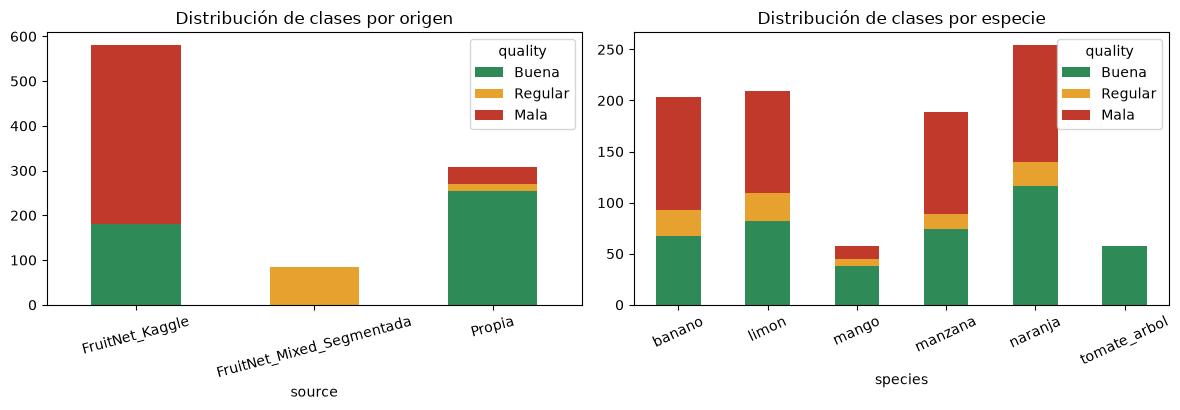

In [3]:
# Análisis de resoluciones y relación de aspecto (evidencia la variabilidad entre cámaras y orígenes)
df["aspect_ratio"] = (df["width"] / df["height"]).round(2)
display(df.groupby("source")[["width", "height", "aspect_ratio"]].agg(["min", "median", "max"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ct_src = pd.crosstab(df["source"], df["quality"]).reindex(columns=list(QUALITY_CLASSES), fill_value=0)
ct_src.plot(kind="bar", stacked=True, ax=axes[0], color=["#2E8B57", "#E6A12E", "#C0392B"])
axes[0].set_title("Distribución de clases por origen")
axes[0].tick_params(axis="x", rotation=15)

ct_sp = pd.crosstab(df["species"], df["quality"]).reindex(columns=list(QUALITY_CLASSES), fill_value=0)
ct_sp.plot(kind="bar", stacked=True, ax=axes[1], color=["#2E8B57", "#E6A12E", "#C0392B"])
axes[1].set_title("Distribución de clases por especie")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

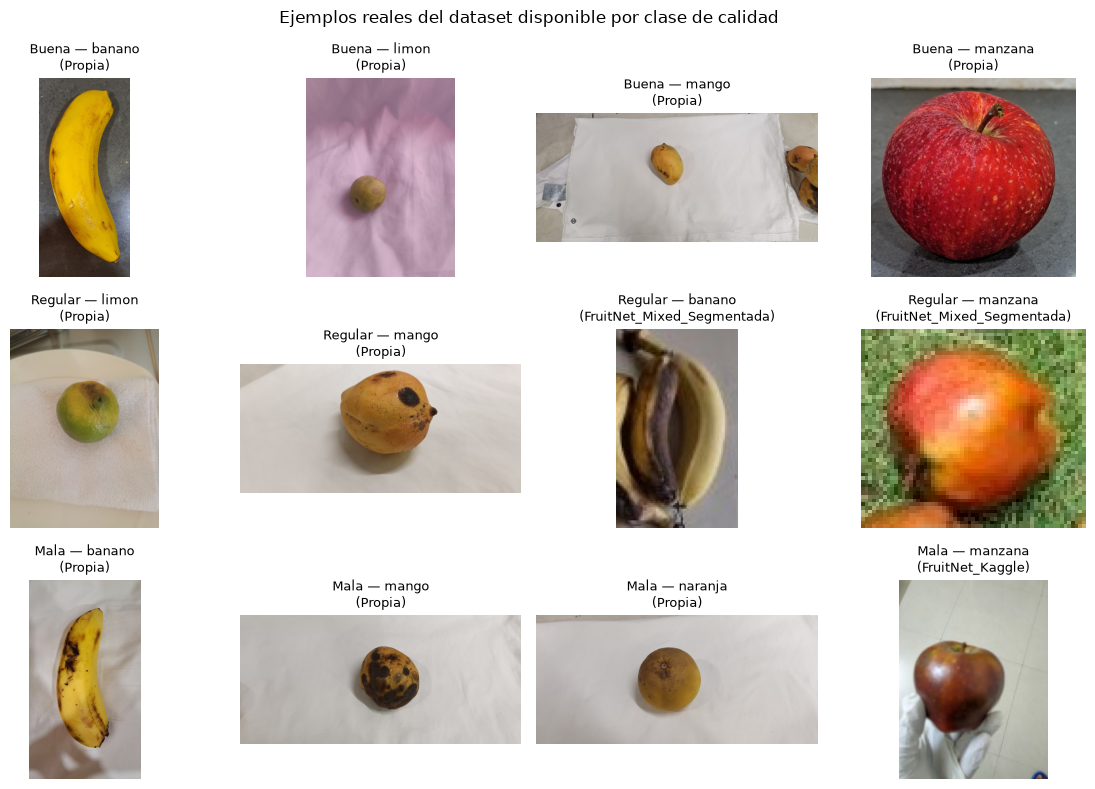

In [4]:
# Galería de muestras reales por clase (Buena, Regular, Mala) tolerante a ausencia de data/external/
available_mask = df["image_path"].apply(lambda rel: (PROJECT_ROOT / str(rel)).is_file())
avail_df = df[available_mask].copy()
missing_ext = int((~available_mask).sum())
if missing_ext > 0:
    print(
        f"Aviso: {missing_ext} imágenes externas de Kaggle (data/external/) no están presentes localmente. "
        "Para descargarlas, consulta data/README.md (Fruit Quality Classification). Se muestran las fotos versionadas."
    )

fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for r_idx, cls in enumerate(QUALITY_CLASSES):
    sub = avail_df[avail_df["quality"].eq(cls)]
    picks = sub.groupby("species", group_keys=False).head(1).head(4)
    if len(picks) < 4:
        picks = sub.head(4)
    for c_idx in range(4):
        ax = axes[r_idx, c_idx]
        ax.axis("off")
        if c_idx < len(picks):
            row = picks.iloc[c_idx]
            img = Image.open(PROJECT_ROOT / str(row["image_path"])).convert("RGB")
            ax.imshow(img)
            ax.set_title(f"{cls} — {row['species']}\n({row['source']})", fontsize=9)
plt.suptitle("Ejemplos reales del dataset disponible por clase de calidad", fontsize=12)
plt.tight_layout()
plt.show()

=== Calidad cuantitativa de imagen por origen (sobre imágenes disponibles en disco) ===


,n,brillo_L_mediana,contraste_L_mediana,nitidez_lap_mediana,pct_fondo_oscuro
source,,,,,
FruitNet_Kaggle,580,67.59,20.91,185.83,5.3
FruitNet_Mixed_Segmentada,84,55.04,21.17,2300.34,22.6
Propia,307,72.94,12.27,75.87,6.5


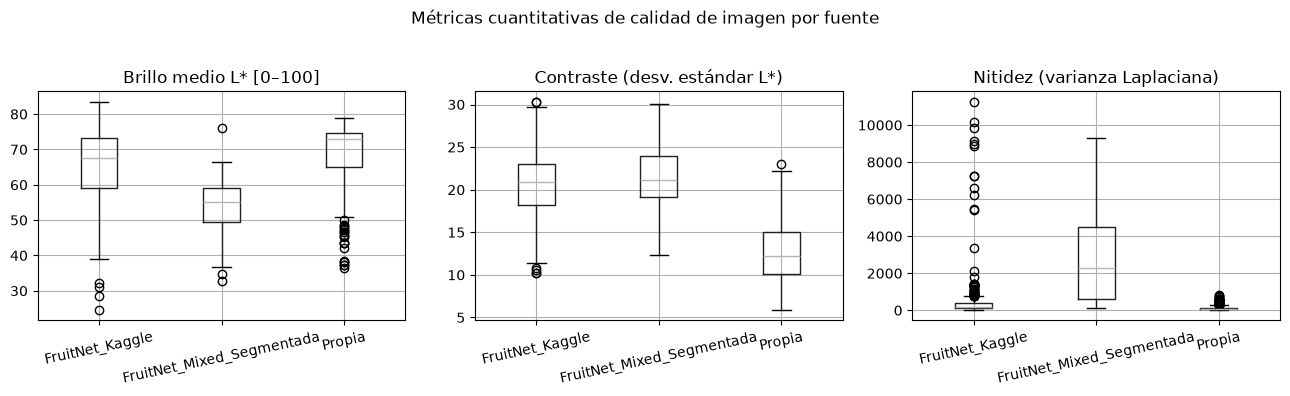

In [5]:
# Análisis cuantitativo de calidad de imagen (brillo L*, contraste, nitidez Laplaciana y fondo oscuro)
import cv2

qual_rows = []
for _, row in avail_df.iterrows():
    img_path = PROJECT_ROOT / str(row["image_path"])
    rgb = np.asarray(Image.open(img_path).convert("RGB"))
    # Redimensionar lado mayor a 256 px para comparar nitidez/brillo en escala homogénea
    h, w = rgb.shape[:2]
    scale = min(1.0, 256.0 / max(h, w))
    if scale < 1.0:
        rgb_s = cv2.resize(rgb, (max(16, int(w * scale)), max(16, int(h * scale))), interpolation=cv2.INTER_AREA)
    else:
        rgb_s = rgb
    lab = cv2.cvtColor(rgb_s, cv2.COLOR_RGB2LAB).astype(np.float32)
    l_cie = lab[:, :, 0] * (100.0 / 255.0)
    gray = cv2.cvtColor(rgb_s, cv2.COLOR_RGB2GRAY)
    sharpness = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    # Brillo mediano del marco exterior (7 %) para identificar fondos oscuros vs. claros
    sh, sw = l_cie.shape
    bh, bw = max(2, int(sh * 0.07)), max(2, int(sw * 0.07))
    border_l = np.concatenate([
        l_cie[:bh, :].ravel(), l_cie[-bh:, :].ravel(),
        l_cie[bh:-bh, :bw].ravel(), l_cie[bh:-bh, -bw:].ravel()
    ])
    qual_rows.append({
        "source": row["source"],
        "species": row["species"],
        "quality": row["quality"],
        "brightness_L": float(l_cie.mean()),
        "contrast_L_std": float(l_cie.std()),
        "sharpness_lap_var": sharpness,
        "dark_background": float(np.median(border_l)) < 45.0,
    })

iq_df = pd.DataFrame(qual_rows)
print("=== Calidad cuantitativa de imagen por origen (sobre imágenes disponibles en disco) ===")
summary_iq = iq_df.groupby("source").agg(
    n=("brightness_L", "count"),
    brillo_L_mediana=("brightness_L", "median"),
    contraste_L_mediana=("contrast_L_std", "median"),
    nitidez_lap_mediana=("sharpness_lap_var", "median"),
    pct_fondo_oscuro=("dark_background", lambda s: round(float(s.mean() * 100), 1)),
).round(2)
display(summary_iq)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
iq_df.boxplot(column="brightness_L", by="source", ax=axes[0])
axes[0].set_title("Brillo medio L* [0–100]")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=12)

iq_df.boxplot(column="contrast_L_std", by="source", ax=axes[1])
axes[1].set_title("Contraste (desv. estándar L*)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=12)

iq_df.boxplot(column="sharpness_lap_var", by="source", ax=axes[2])
axes[2].set_title("Nitidez (varianza Laplaciana)")
axes[2].set_xlabel("")
axes[2].tick_params(axis="x", rotation=12)
plt.suptitle("Métricas cuantitativas de calidad de imagen por fuente", y=1.03)
plt.tight_layout()
plt.show()

=== Distribución de categorías de tamaño en fotos propias (n=307) ===


size_category,Grande,Mediano,Pequeño,All
species,,,,
banano,30,2,0,32
limon,0,43,2,45
mango,0,18,40,58
manzana,16,4,9,29
naranja,0,17,68,85
tomate_arbol,0,1,57,58
All,46,85,176,307


,count,min,median,mean,max
species,,,,,
banano,32,0.5293,0.7964,0.7899,1.0000
limon,45,0.1860,0.3880,0.3912,0.5240
mango,58,0.1475,0.2617,0.2771,0.4580
manzana,29,0.2129,0.8096,0.6127,0.9639
naranja,85,0.1631,0.2580,0.2574,0.4150
tomate_arbol,58,0.0684,0.1984,0.1990,0.3080


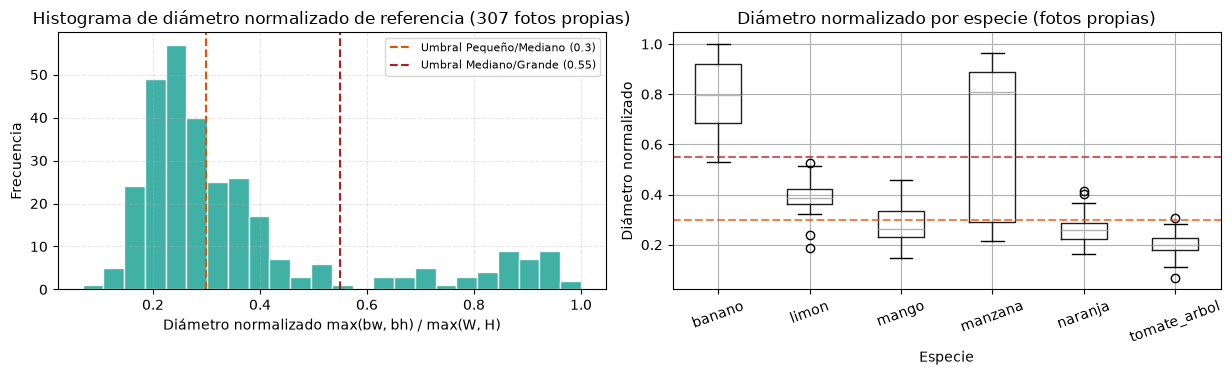

In [6]:
# Distribución exploratoria de tamaño relativo en las 307/307 fotos propias
from src.size_estimation import DEFAULT_SIZE_THRESHOLDS

print("=== Distribución de categorías de tamaño en fotos propias (n=307) ===")
display(pd.crosstab(own_df["species"], own_df["size_category"], margins=True))
display(own_df.groupby("species")["reference_normalized_diameter"].agg(["count", "min", "median", "mean", "max"]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))
axes[0].hist(own_df["reference_normalized_diameter"], bins=24, color="#26A69A", edgecolor="white", alpha=0.88)
axes[0].axvline(DEFAULT_SIZE_THRESHOLDS[0], color="#E65100", linestyle="--", label=f"Umbral Pequeño/Mediano ({DEFAULT_SIZE_THRESHOLDS[0]})")
axes[0].axvline(DEFAULT_SIZE_THRESHOLDS[1], color="#B71C1C", linestyle="--", label=f"Umbral Mediano/Grande ({DEFAULT_SIZE_THRESHOLDS[1]})")
axes[0].set_title("Histograma de diámetro normalizado de referencia (307 fotos propias)")
axes[0].set_xlabel("Diámetro normalizado max(bw, bh) / max(W, H)")
axes[0].set_ylabel("Frecuencia")
axes[0].legend(fontsize=8)
axes[0].grid(True, linestyle="--", alpha=0.3)

own_df.boxplot(column="reference_normalized_diameter", by="species", ax=axes[1])
axes[1].axhline(DEFAULT_SIZE_THRESHOLDS[0], color="#E65100", linestyle="--", alpha=0.7)
axes[1].axhline(DEFAULT_SIZE_THRESHOLDS[1], color="#B71C1C", linestyle="--", alpha=0.7)
axes[1].set_title("Diámetro normalizado por especie (fotos propias)")
axes[1].set_xlabel("Especie")
axes[1].set_ylabel("Diámetro normalizado")
axes[1].tick_params(axis="x", rotation=20)
plt.suptitle("")
plt.tight_layout()
plt.show()

### Hallazgos clave del EDA
1. **Desbalanceo controlado y sesgo de origen:** `Buena` (~44.8 %) y `Mala` (~45.0 %) están equilibradas, mientras `Regular` representa ~10.2 % (`99` imágenes: `15` propias + `84` recortes validados de `Mixed Qualit_Fruits`). Esto exige usar **pesos por clase** y **Macro-F1**, y vigilar en Fase 5 un posible **atajo de resolución/origen** (*shortcut learning*), ya que el 100 % de `Mixed` tiene resolución mediana `52×55 px` y clase `Regular`.
2. **Heterogeneidad de captura y calidad de imagen:** las fotos propias varían entre formato horizontal panorámico (`1024×468`, tela blanca), vertical (`768×1024`, limones) y primer plano sobre mesón gris oscuro (`banano`, `manzana`), lo que se refleja en la proporción de fondos oscuros y la varianza de brillo/nitidez entre fuentes.
3. **Distribución de tamaños (307/307 propias):** `banano` y `manzana` (primeros planos) concentran los valores `Grande` (`≥ 0.55`), `limon` domina en `Mediano` (`0.30–0.55`), y `naranja`, `mango` y `tomate_arbol` predominan en `Pequeño` (`< 0.30`).
4. **Cobertura por especie:** `tomate_arbol` (`58`) y `manzana` propia (`29`) solo cuentan con ejemplares `Buena` en las capturas propias; se seleccionaron únicamente las 4 especies de Kaggle compartidas con la recolección local (`Apple`, `Banana`, `Lime/Lemon`, `Orange`).